In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


<Axes: xlabel='size_m2', ylabel='price'>

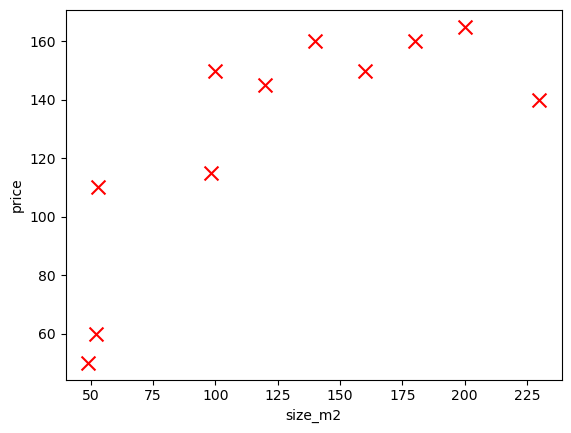

In [2]:
df = pd.DataFrame({
    'size_m2': [49, 52, 53, 98, 100, 120, 140, 160, 180, 200, 230],
    'price': [50, 60, 110, 115, 150, 145, 160, 150, 160, 165, 140]
})

df.plot(x='size_m2', y='price', kind='scatter', marker='x', color='red', s=100)

# So this is our hypothesis for the linear regression

$$ h(x) = \theta_0 + \theta_1 \cdot x$$


In [3]:
theta_0 = 0
theta_1 = 1

m = len(df)

# Let's plug them into the linear model

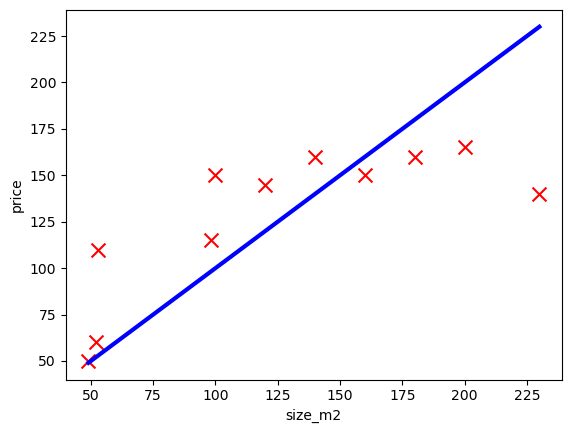

In [4]:
df['prediction'] = theta_0 + theta_1 * df['size_m2']

df.plot(x='size_m2', y='price', kind='scatter', marker='x', color='red', s=100)
plt.plot(df['size_m2'], df['prediction'], color='blue', linestyle='-', linewidth=3)

plt.show()

In [5]:
mse_loss = 1 / (2 * m) * np.sum((df['prediction'] - df['price']) ** 2)
print(mse_loss)

770.5909090909091


# Polynomial regression
Quadratic function

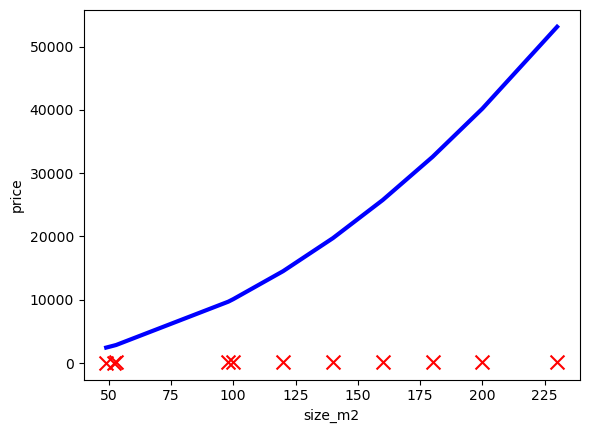

In [6]:
theta_0 = 0
theta_1 = 1
theta_2 = 1

df['prediction'] = theta_2 * (df['size_m2']**2) + theta_1 * df['size_m2'] + theta_0

df.plot(x='size_m2', y='price', kind='scatter', marker='x', color='red', s=100)
plt.plot(df['size_m2'], df['prediction'], color='blue', linestyle='-', linewidth=3)

plt.show()

In [7]:
mse_loss = 1 / (2 * m) * np.sum((df['prediction'] - df['price']) ** 2)
print(mse_loss)

314509174.5


Cubic function

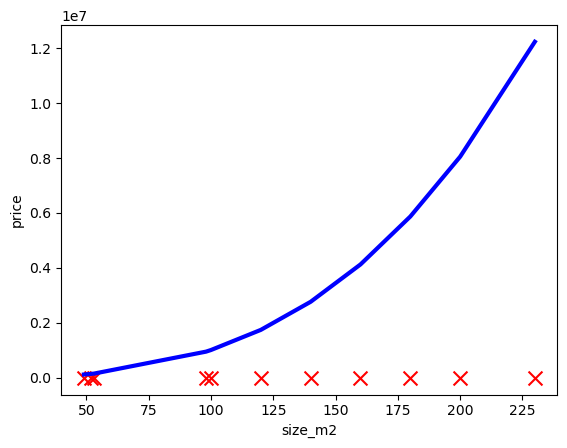

In [8]:
theta_0 = -100
theta_1 = 1
theta_2 = 1
theta_3 = 1

df['prediction'] = (theta_0 + 
                    theta_1 * df['size_m2'] + 
                    theta_2 * (df['size_m2']**2) + 
                    theta_3 * (df['size_m2']**3))

df.plot(x='size_m2', y='price', kind='scatter', marker='x', color='red', s=100)
plt.plot(df['size_m2'], df['prediction'], color='blue', linestyle='-', linewidth=3)

plt.show()

In [10]:
mse_loss = 1/(2*m) * ((df['prediction'] - df['price']) ** 2).sum()
mse_loss

12636233991565.863

# Gradient descent

So will take loss as
$$ Loss(\theta_0, \theta_1) = \frac{1}{2m} \sum_{i=1}^{m} \left( \text{prediction}_i - \text{actual}_i \right)^2 $$

We will use partial derivatives for theta_0 as:
$$ \frac{\partial Loss}{\partial \theta_0} = \frac{1}{m} \sum_{i=1}^{m} \left( \text{prediction}_i - \text{actual}_i \right) $$

We will use partial derivatives for theta_1 as:
$$ \frac{\partial Loss}{\partial \theta_1} = \frac{1}{m} \sum_{i=1}^{m} \left( \text{prediction}_i - \text{actual}_i \right) \times \text{size\_m2}_i $$

Using update rules for theta_0 and theta_1:
$$ \theta_0 := \theta_0 - \alpha \times \frac{\partial Loss}{\partial \theta_0} $$

$$ \theta_1 := \theta_1 - \alpha \times \frac{\partial Loss}{\partial \theta_1} $$


In [23]:
df['size_m2_normalised'] = (df['size_m2'] - df['size_m2'].mean()) / (df['size_m2'].max() - df['size_m2'].min())
df['size_m2_normalised'].describe()

count    1.100000e+01
mean    -2.018587e-17
std      3.440909e-01
min     -4.234053e-01
25%     -2.769965e-01
50%     -3.114013e-02
75%      2.451030e-01
max      5.765947e-01
Name: size_m2_normalised, dtype: float64

Iteration: 0, loss: 8885.227272727272
Iteration: 100, loss: 152.39829894436184
Iteration: 200, loss: 121.65839755171731
Iteration: 300, loss: 116.80586186446779
Iteration: 400, loss: 115.92015709534859
Iteration: 500, loss: 115.65483304537504
Iteration: 600, loss: 115.4977074871749
Iteration: 700, loss: 115.36922213759443
Iteration: 800, loss: 115.25597612443707
Iteration: 900, loss: 115.15479427157341
Iteration: 1000, loss: 115.06417923556427
Iteration: 1100, loss: 114.98299502158748
Iteration: 1200, loss: 114.91025515502588
Iteration: 1300, loss: 114.84508054389549
Iteration: 1400, loss: 114.78668425408306
Iteration: 1500, loss: 114.73436130574314
Iteration: 1600, loss: 114.68748005543348
Iteration: 1700, loss: 114.64547455456312
Iteration: 1800, loss: 114.60783771478917
Iteration: 1900, loss: 114.57411518609115
Iteration: 2000, loss: 114.54389987182293
Iteration: 2100, loss: 114.5168270142528
Iteration: 2200, loss: 114.49256979122673
Iteration: 2300, loss: 114.470835370787
Iteration

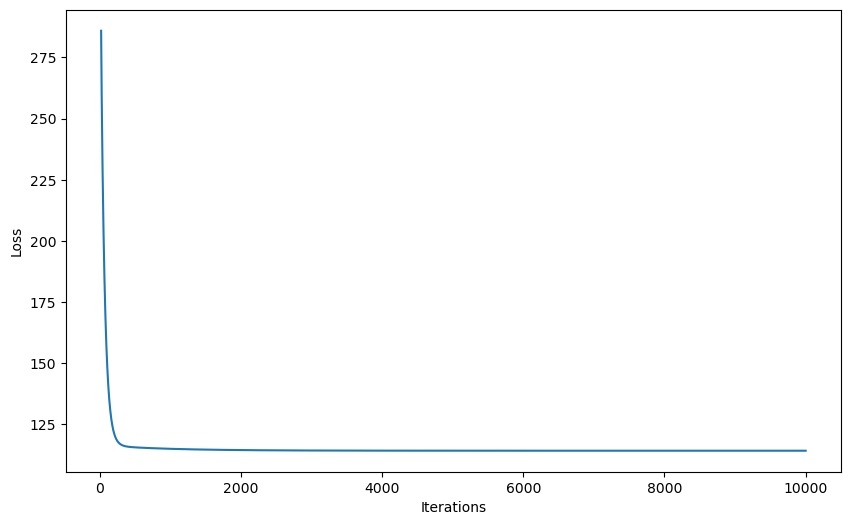

In [41]:
theta_0 = 0.0
theta_1 = 0.0
theta_2 = 0.0
theta_3 = 0.0

n_iterations = 10_000
alpha = 1

loss_values = []
intermediate_models = []

for i in range(n_iterations):
    predictions = (theta_0 + 
                   theta_1 * df['size_m2_normalised'] + 
                   theta_2 * (df['size_m2_normalised']**2) +
                   theta_3 * (df['size_m2_normalised']**3))
    
    loss = 1 / (2 * m) * ((predictions - df['price']) ** 2).sum()
    loss_values.append(loss)
    
    if i % 100 == 0:
        print(f'Iteration: {i}, loss: {loss}')
    
    gradient_theta_0 = (1 / m) * (predictions - df['price']).sum()
    gradient_theta_1 = (1 / m) * np.sum((predictions - df['price']) * df['size_m2_normalised'])
    gradient_theta_2 = (1 / m) * np.sum((predictions - df['price']) * (df['size_m2_normalised']**2))
    gradient_theta_3 = (1 / m) * np.sum((predictions - df['price']) * (df['size_m2_normalised']**3))
    
    theta_0 = theta_0 - alpha * gradient_theta_0
    theta_1 = theta_1 - alpha * gradient_theta_1
    theta_2 = theta_2 - alpha * gradient_theta_2
    theta_3 = theta_3 - alpha * gradient_theta_3
    
    intermediate_models.append((theta_0, theta_1, theta_2, theta_3))

plt.figure(figsize=(10, 6))
# plt.plot(range(1, n_iterations+1), loss_values)
plt.plot(range(20, n_iterations+1), loss_values[19:])
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.show()

In [42]:
intermediate_models[-1]

(150.42131232082582, 89.40710182944376, -215.6145991789478, 69.5962845908878)

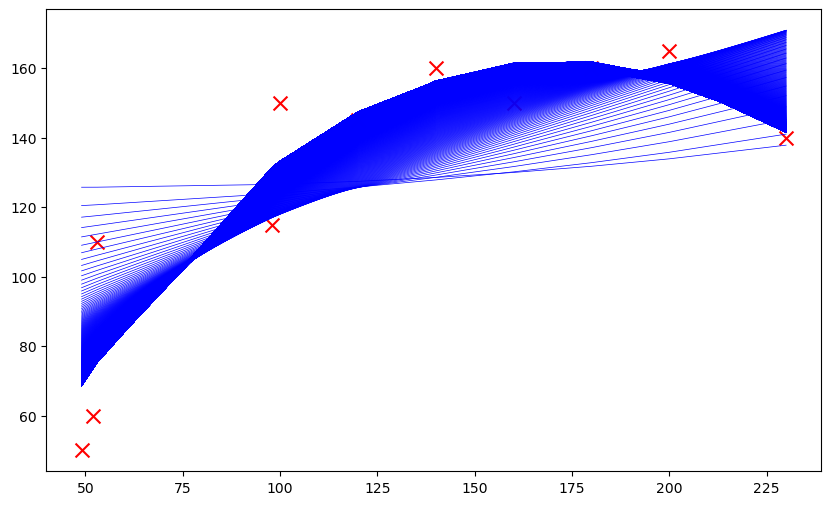

In [46]:
plt.figure(figsize=(10, 6))
plt.scatter(df['size_m2'], df['price'], marker='x', color='red', s=100, label='Actual')

for i, model in enumerate(intermediate_models):
    predictions = (model[0] + 
                   model[1] * df['size_m2_normalised'] + 
                   model[2] * (df['size_m2_normalised']**2) + 
                   model[3] * (df['size_m2_normalised']**3))
    
    plt.plot(df['size_m2'], predictions, color='blue', linestyle='-', linewidth=0.5)

plt.show()